# Tasks for laboratory assignment 3

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    r2_score,
)

os.makedirs("images", exist_ok=True)

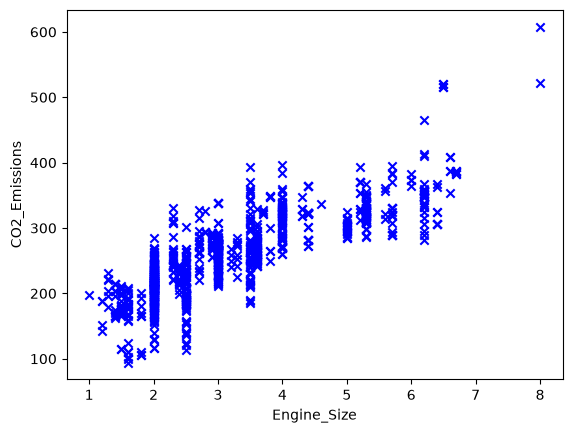

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    return pd.read_csv(file_path)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

In [4]:
def select_polynomial_degree(X, y, degrees=range(1, 6)):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = {}
    for degree in degrees:
        model = make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression())
        scores[degree] = cross_val_score(model, X, y, cv=cv, scoring="r2").mean()
    scores = pd.Series(scores, name="CV R2")
    best = scores.idxmax()
    if best > 1 and scores[best] - scores[best - 1] < 0.005:
        best -= 1
    return best, scores


def fit_polynomial(X, y, degree):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    features = PolynomialFeatures(degree, include_bias=False)
    model = LinearRegression().fit(features.fit_transform(X_train), y_train)
    predictions = model.predict(features.transform(X_test))
    print(f"degree={degree}  test R2={r2_score(y_test, predictions):.4f}  test MAE={mean_absolute_error(y_test, predictions):.3f}")
    model.fit(features.fit_transform(X), y)
    theta = [float(model.intercept_)] + [float(c) for c in model.coef_]
    return features, model, theta


def plot_degree_scores(scores, title, file_name):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    scores.plot(ax=ax, marker="o")
    ax.set_xlabel("polynomial degree")
    ax.set_ylabel("5-fold CV R2")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(f"images/{file_name}", dpi=120)
    plt.show()


def regression_1d(data, x, y, name):
    X = data[[x]].to_numpy()
    target = data[y].to_numpy()
    degree, scores = select_polynomial_degree(X, target)
    print(scores.round(4).to_string())
    plot_degree_scores(scores, f"{name}: model selection", f"{name}_degree_selection.png")
    features, model, theta = fit_polynomial(X, target, degree)

    grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(X, target, c="tab:blue", marker="x", alpha=0.6, label="data")
    ax.plot(grid, model.predict(features.transform(grid)), color="tab:red", linewidth=2, label=f"polynomial regression, degree {degree}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"images/{name}_model.png", dpi=120)
    plt.show()
    return theta

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

1    0.6749
2    0.6795
3    0.6895
4    0.7002
5    0.6991


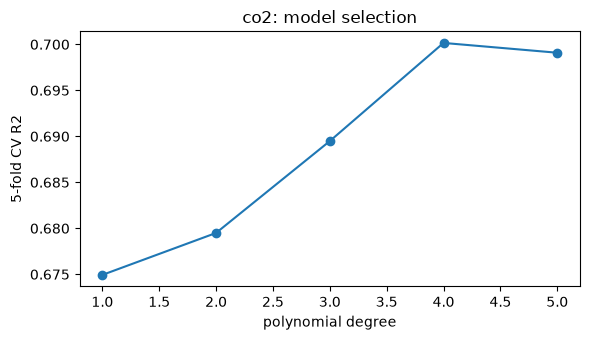

degree=4  test R2=0.6671  test MAE=27.746


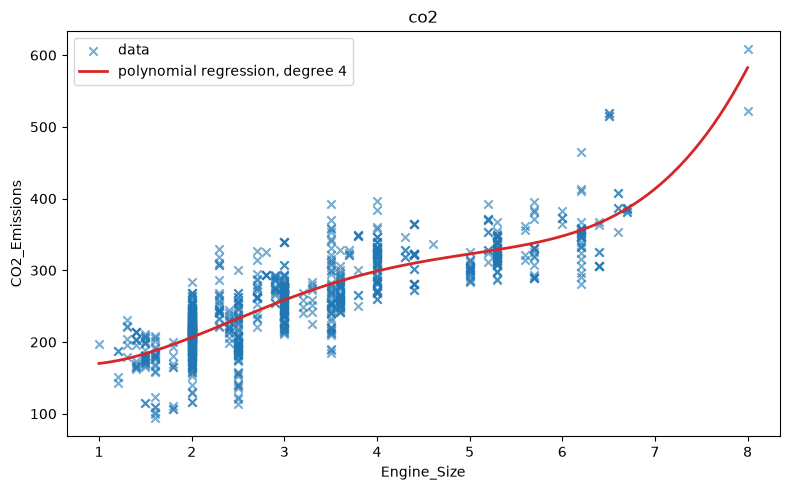

[198.97238447804287,
 -83.53403051639569,
 67.64874311728668,
 -13.857801595519833,
 0.9320101257868032]

In [5]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    return regression_1d(data, "Engine_Size", "CO2_Emissions", "co2")

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

1   -0.2356
2    0.9093
3    0.9127
4    0.9152
5    0.9108


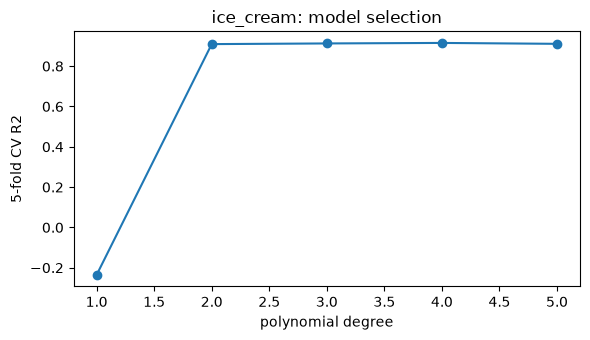

degree=3  test R2=0.8405  test MAE=3.228


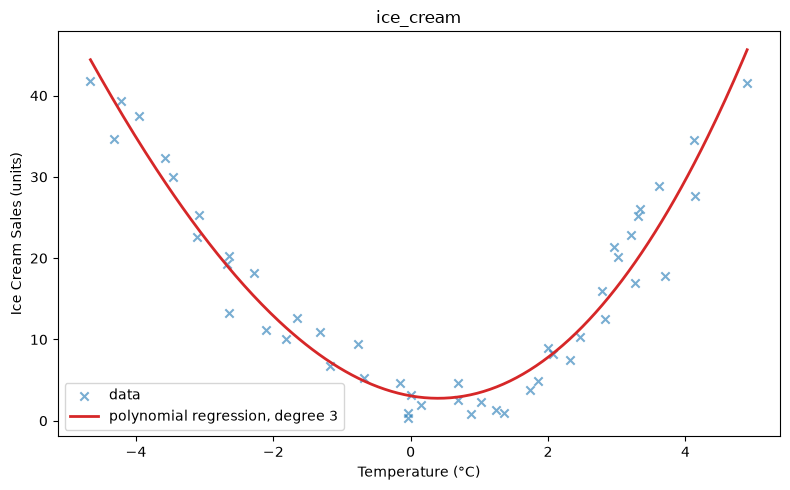

[3.061373017339175,
 -1.4809035312338679,
 1.8243120995404396,
 0.051412741659930594]

In [6]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    return regression_1d(data, "Temperature (°C)", "Ice Cream Sales (units)", "ice_cream")

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

1    0.2451
2    0.2878
3    0.3007
4    0.3054


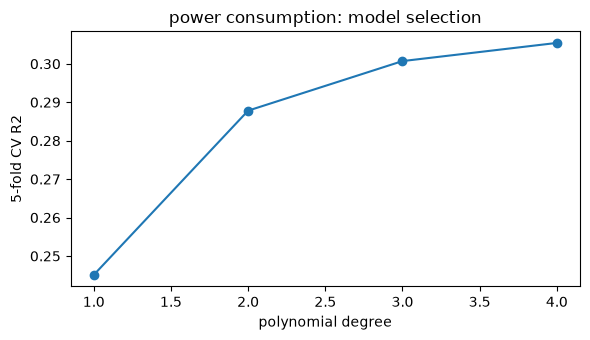

degree=3  test R2=0.3038  test MAE=11403.794
intercept                         176649.877
Temperature                         1217.495
Humidity                           -4953.926
WindSpeed                              7.203
Temperature^2                       -246.010
Temperature Humidity                  50.962
Temperature WindSpeed               -293.157
Humidity^2                            67.685
Humidity WindSpeed                   -85.470
WindSpeed^2                           93.259
Temperature^3                          4.220
Temperature^2 Humidity                 1.255
Temperature^2 WindSpeed                4.624
Temperature Humidity^2                -0.420
Temperature Humidity WindSpeed        -2.425
Temperature WindSpeed^2               72.141
Humidity^3                            -0.326
Humidity^2 WindSpeed                  -0.739
Humidity WindSpeed^2                  41.255
WindSpeed^3                         -222.354


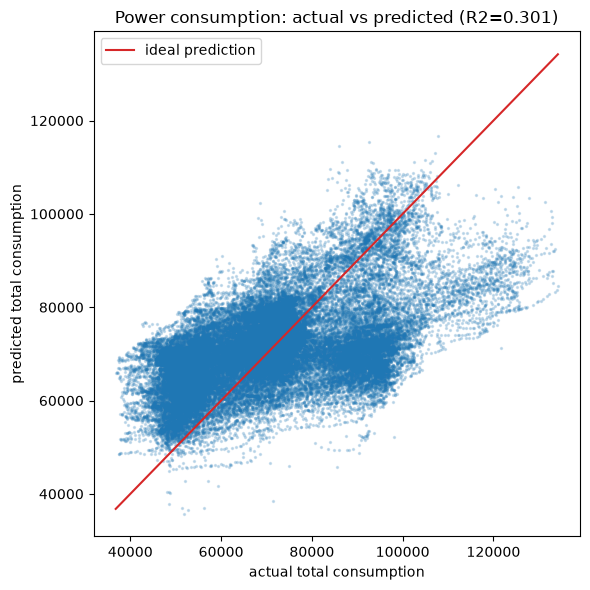

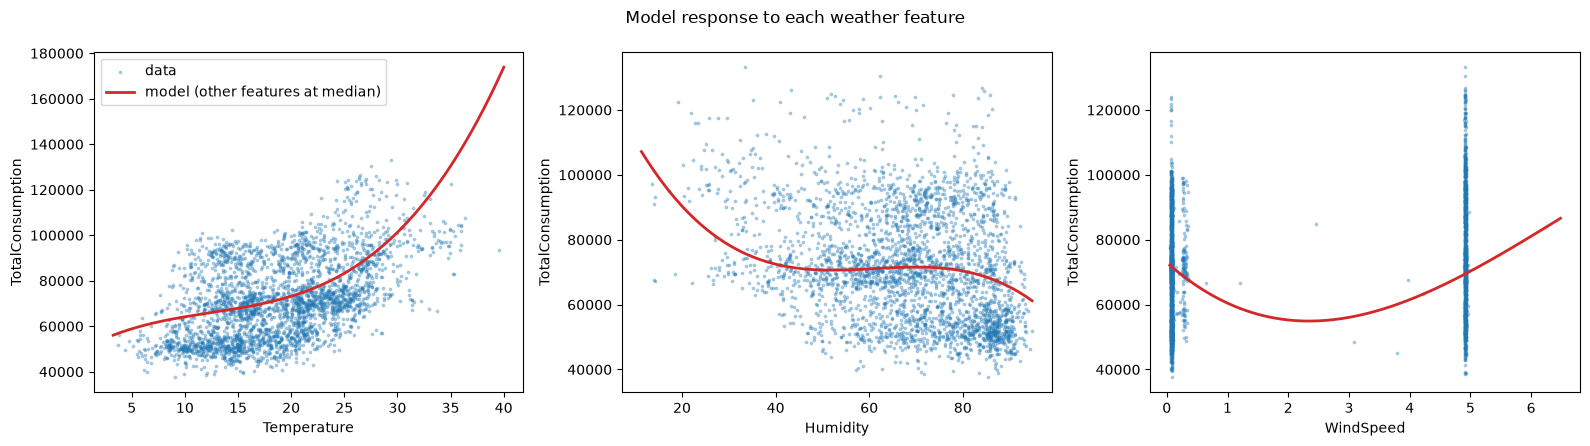

[176649.87668581033,
 1217.4945280270313,
 -4953.925935627331,
 7.203468038051918,
 -246.0097981759389,
 50.96171084577121,
 -293.1572104528429,
 67.68532814599153,
 -85.47035693393617,
 93.258814240203,
 4.220408820322203,
 1.2554500828883037,
 4.623880399671087,
 -0.4204128406343433,
 -2.424641039791465,
 72.14078318125473,
 -0.3263002343893294,
 -0.7387503654732532,
 41.25505213741418,
 -222.35371115620248]

In [7]:
WEATHER = ["Temperature", "Humidity", "WindSpeed"]


def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed.
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    zones = [column for column in data.columns if column.startswith("PowerConsumption")]
    data = data.assign(TotalConsumption=data[zones].sum(axis=1))
    X = data[WEATHER].to_numpy()
    y = data["TotalConsumption"].to_numpy()

    degree, scores = select_polynomial_degree(X, y, degrees=range(1, 5))
    print(scores.round(4).to_string())
    plot_degree_scores(scores, "power consumption: model selection", "power_degree_selection.png")
    features, model, theta = fit_polynomial(X, y, degree)
    print(pd.Series(theta, index=["intercept"] + list(features.get_feature_names_out(WEATHER))).round(3).to_string())

    predictions = model.predict(features.transform(X))
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y, predictions, s=2, alpha=0.2)
    limits = [y.min(), y.max()]
    ax.plot(limits, limits, color="tab:red", label="ideal prediction")
    ax.set_xlabel("actual total consumption")
    ax.set_ylabel("predicted total consumption")
    ax.set_title(f"Power consumption: actual vs predicted (R2={r2_score(y, predictions):.3f})")
    ax.legend()
    fig.tight_layout()
    fig.savefig("images/power_actual_vs_predicted.png", dpi=120)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    medians = data[WEATHER].median()
    for ax, feature in zip(axes, WEATHER):
        grid = np.tile(medians.to_numpy(), (200, 1))
        grid[:, WEATHER.index(feature)] = np.linspace(data[feature].min(), data[feature].max(), 200)
        sample = data.sample(3000, random_state=42)
        ax.scatter(sample[feature], sample["TotalConsumption"], s=3, alpha=0.3, label="data")
        ax.plot(grid[:, WEATHER.index(feature)], model.predict(features.transform(grid)), color="tab:red", linewidth=2, label="model (other features at median)")
        ax.set_xlabel(feature)
        ax.set_ylabel("TotalConsumption")
    axes[0].legend()
    fig.suptitle("Model response to each weather feature")
    fig.tight_layout()
    fig.savefig("images/power_feature_effects.png", dpi=120)
    plt.show()
    return theta

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

logistic regression (L1)    0.8503
ridge classifier            0.8502
logistic regression         0.8326
SGD classifier              0.7712

features kept by L1 regularization (18 of 22): ['sex', 'trtbps', 'chol', 'thalachh', 'exng', 'oldpeak', 'cp_1', 'cp_2', 'cp_3', 'restecg_1', 'slp_1', 'slp_2', 'caa_1', 'caa_2', 'caa_3', 'caa_4', 'thall_2', 'thall_3']

best model: logistic regression (L1)
validation accuracy=0.7895  f1=0.8140
              precision    recall  f1-score   support

    low risk       0.81      0.71      0.76        35
   high risk       0.78      0.85      0.81        41

    accuracy                           0.79        76
   macro avg       0.79      0.78      0.79        76
weighted avg       0.79      0.79      0.79        76



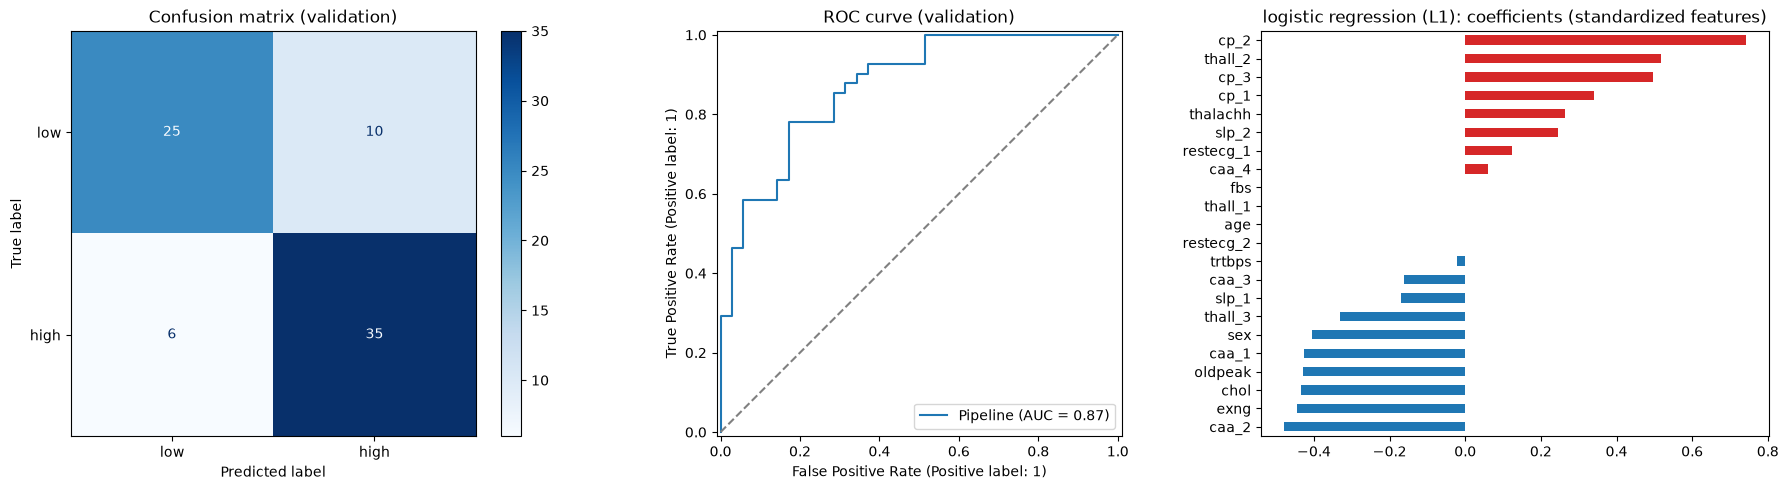

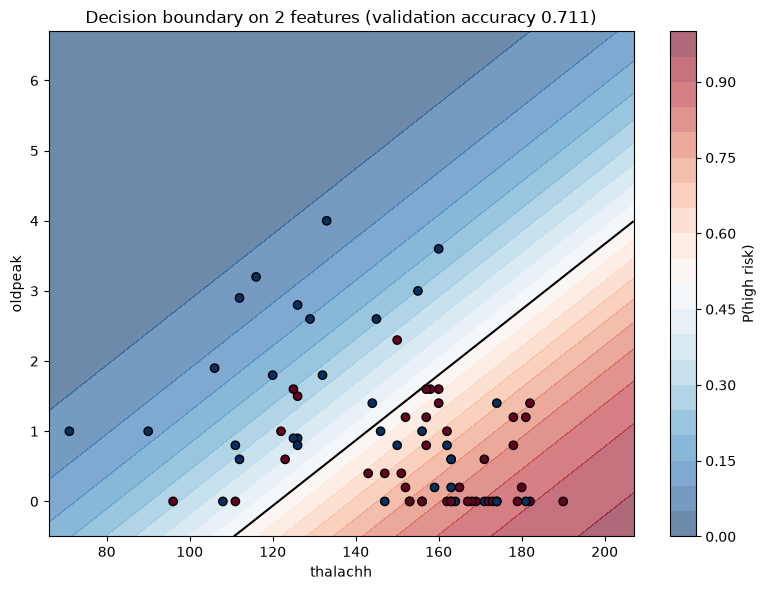

[0.15711269314073,
 0.0,
 -0.40498810976529337,
 -0.020560826511644398,
 -0.4352787887824619,
 0.0,
 0.26268779901682804,
 -0.44425885978518437,
 -0.42997311262696675,
 0.33991833438809155,
 0.7413678648362909,
 0.49716729703065976,
 0.12273580288863888,
 0.0,
 -0.1709927061327569,
 0.2454649107464994,
 -0.4252697556927917,
 -0.4789033043501958,
 -0.1616233967329183,
 0.059602672029312305,
 0.0,
 0.5180865128733095,
 -0.3311343120836588]

In [8]:
CATEGORICAL = ["cp", "restecg", "slp", "caa", "thall"]


def heart_features(data):
    return pd.get_dummies(data.drop(columns="output"), columns=CATEGORICAL, drop_first=True, dtype=float)


def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    X = heart_features(data)
    y = data["output"]
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    candidates = {
        "logistic regression": LogisticRegression(max_iter=5000),
        "logistic regression (L1)": LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.5),
        "ridge classifier": RidgeClassifier(),
        "SGD classifier": SGDClassifier(loss="log_loss", random_state=42),
    }
    results = {}
    for name, estimator in candidates.items():
        model = make_pipeline(StandardScaler(), estimator)
        results[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    results = pd.Series(results, name="5-fold CV accuracy").sort_values(ascending=False)
    print(results.round(4).to_string())

    selector = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.5)).fit(X_train, y_train)
    selected = X.columns[np.abs(selector[-1].coef_[0]) > 1e-6]
    print(f"\nfeatures kept by L1 regularization ({len(selected)} of {X.shape[1]}): {list(selected)}")

    best_name = results.index[0]
    model = make_pipeline(StandardScaler(), candidates[best_name]).fit(X_train, y_train)
    predictions = model.predict(X_val)
    print(f"\nbest model: {best_name}")
    print(f"validation accuracy={accuracy_score(y_val, predictions):.4f}  f1={f1_score(y_val, predictions):.4f}")
    print(classification_report(y_val, predictions, target_names=["low risk", "high risk"]))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ConfusionMatrixDisplay.from_predictions(y_val, predictions, display_labels=["low", "high"], cmap="Blues", ax=axes[0])
    axes[0].set_title("Confusion matrix (validation)")
    RocCurveDisplay.from_estimator(model, X_val, y_val, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_title("ROC curve (validation)")
    coefficients = pd.Series(np.ravel(model[-1].coef_), index=X.columns).sort_values()
    coefficients.plot.barh(ax=axes[2], color=np.where(coefficients > 0, "tab:red", "tab:blue"))
    axes[2].set_title(f"{best_name}: coefficients (standardized features)")
    fig.tight_layout()
    fig.savefig("images/heart_classification.png", dpi=120)
    plt.show()

    two = ["thalachh", "oldpeak"]
    plane = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train[two], y_train)
    xx, yy = np.meshgrid(
        np.linspace(X[two[0]].min() - 5, X[two[0]].max() + 5, 300),
        np.linspace(X[two[1]].min() - 0.5, X[two[1]].max() + 0.5, 300),
    )
    probability = plane.predict_proba(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=two))[:, 1].reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(8, 6))
    contour = ax.contourf(xx, yy, probability, levels=20, cmap="RdBu_r", alpha=0.6)
    ax.contour(xx, yy, probability, levels=[0.5], colors="black")
    ax.scatter(X_val[two[0]], X_val[two[1]], c=y_val, cmap="RdBu_r", edgecolor="black")
    fig.colorbar(contour, ax=ax, label="P(high risk)")
    ax.set_xlabel(two[0])
    ax.set_ylabel(two[1])
    ax.set_title(f"Decision boundary on 2 features (validation accuracy {plane.score(X_val[two], y_val):.3f})")
    fig.tight_layout()
    fig.savefig("images/heart_decision_boundary.png", dpi=120)
    plt.show()

    return [float(c) for c in np.ravel(model[-1].intercept_)] + [float(c) for c in np.ravel(model[-1].coef_)]

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

beta_1=716.357  beta_2=0.997201
test R2=0.9788
 Year  predicted GDP
 2015   9.462174e+12
 2016   9.712780e+12
 2017   9.896436e+12
 2018   1.002932e+13
 2019   1.012457e+13


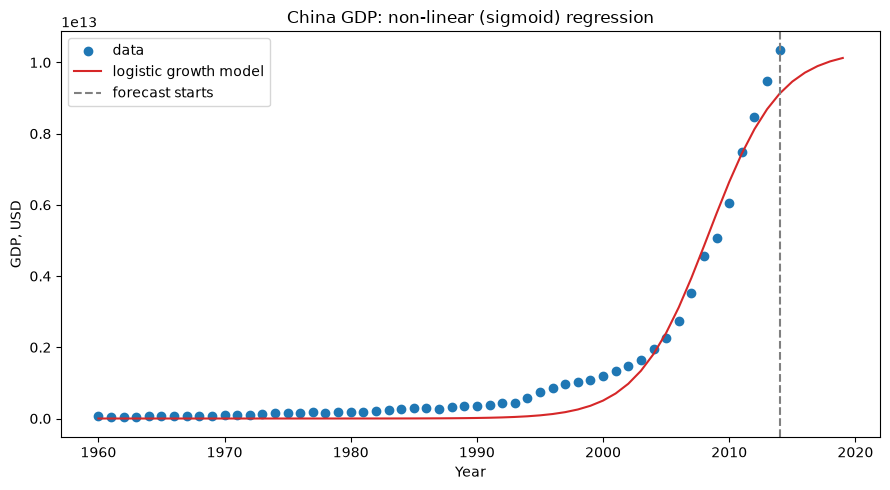

[716.3571364362698, 0.997200836594405]

In [9]:
from scipy.optimize import curve_fit


def logistic_growth(x, beta_1, beta_2):
    return 1 / (1 + np.exp(-beta_1 * (x - beta_2)))


def additional(data):
    x = data["Year"].to_numpy(dtype=float)
    y = data["Value"].to_numpy(dtype=float)
    x_scaled = x / x.max()
    y_scaled = y / y.max()

    x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size=0.2, random_state=42)
    theta, _ = curve_fit(logistic_growth, x_train, y_train, p0=[500, 0.998], maxfev=20000)
    print(f"beta_1={theta[0]:.3f}  beta_2={theta[1]:.6f}")
    print(f"test R2={r2_score(y_test, logistic_growth(x_test, *theta)):.4f}")

    future = np.arange(x.min(), x.max() + 6)
    prediction = logistic_growth(future / x.max(), *theta) * y.max()
    print(pd.DataFrame({"Year": future[-5:].astype(int), "predicted GDP": prediction[-5:]}).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(x, y, label="data")
    ax.plot(future, prediction, color="tab:red", label="logistic growth model")
    ax.axvline(x.max(), color="gray", linestyle="--", label="forecast starts")
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP, USD")
    ax.set_title("China GDP: non-linear (sigmoid) regression")
    ax.legend()
    fig.tight_layout()
    fig.savefig("images/china_gdp_model.png", dpi=120)
    plt.show()
    return [float(t) for t in theta]

data = extract_texts_from_file('resources/china_gdp.csv')
additional(data)

1    0.7286
2    0.8429
3    0.8786
4    1.0000
5    1.0000
6    1.0000
7    1.0000
max_depth=4  test accuracy=0.9833
              precision    recall  f1-score   support

       drugA       0.88      1.00      0.93         7
       drugB       1.00      0.80      0.89         5
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



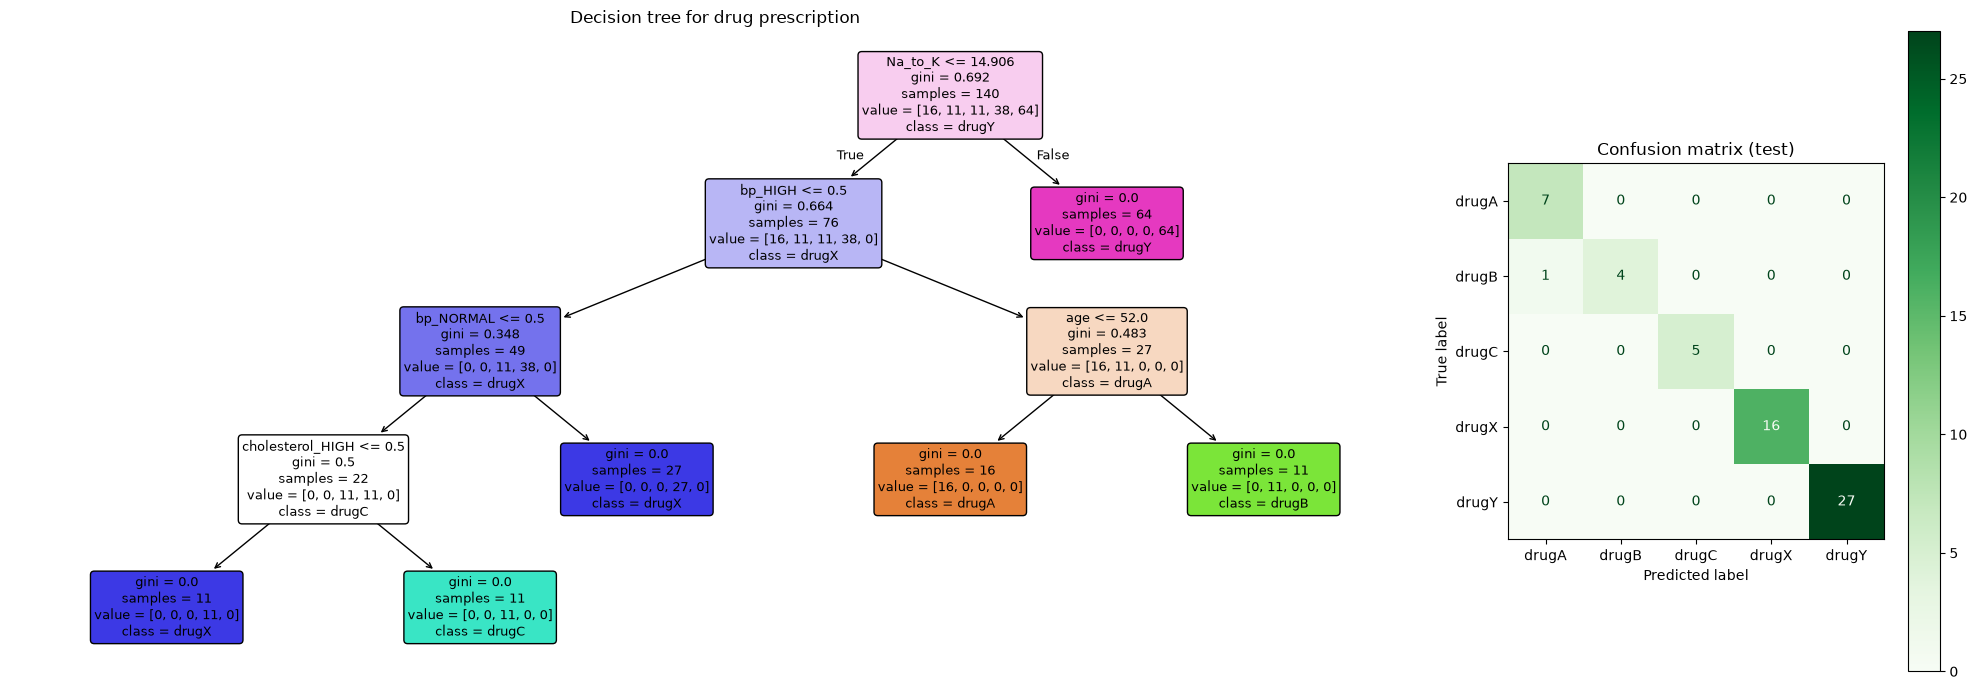

 age sex   bp cholesterol  Na_to_K predicted_drug
  30   F HIGH      NORMAL     12.0          drugA
  65   M  LOW        HIGH      9.5          drugC


In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree


def additional_drug(data):
    X = pd.get_dummies(data.drop(columns="drug"), columns=["sex", "bp", "cholesterol"], dtype=float)
    y = data["drug"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    depths = {depth: cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=42), X_train, y_train, cv=5).mean() for depth in range(1, 8)}
    depth = max(depths, key=depths.get)
    print(pd.Series(depths, name="CV accuracy").round(4).to_string())
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    predictions = tree.predict(X_test)
    print(f"max_depth={depth}  test accuracy={accuracy_score(y_test, predictions):.4f}")
    print(classification_report(y_test, predictions))

    fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [3, 1]})
    plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled=True, rounded=True, ax=axes[0], fontsize=9)
    axes[0].set_title("Decision tree for drug prescription")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Greens", ax=axes[1])
    axes[1].set_title("Confusion matrix (test)")
    fig.tight_layout()
    fig.savefig("images/drug_decision_tree.png", dpi=120)
    plt.show()

    new_patients = pd.DataFrame(
        [{"age": 30, "sex": "F", "bp": "HIGH", "cholesterol": "NORMAL", "Na_to_K": 12.0},
         {"age": 65, "sex": "M", "bp": "LOW", "cholesterol": "HIGH", "Na_to_K": 9.5}]
    )
    new_X = pd.get_dummies(new_patients, columns=["sex", "bp", "cholesterol"], dtype=float).reindex(columns=X.columns, fill_value=0)
    print(new_patients.assign(predicted_drug=tree.predict(new_X)).to_string(index=False))

additional_drug(extract_texts_from_file('resources/drug.csv'))

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.).

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv

Label
1     2469
2     2251
3     5071
4    18054
5    79173


                                accuracy  macro f1  weighted f1  MAE (stars)
model                                                                       
linear SVM (balanced)             0.7678    0.4631       0.7596       0.2883
logistic regression (balanced)    0.7222    0.4619       0.7361       0.3365
logistic regression               0.7813    0.4468       0.7555       0.2749

best model by macro f1: linear SVM (balanced)
              precision    recall  f1-score   support

           1      0.463     0.498     0.480       494
           2      0.238     0.233     0.235       450
           3      0.296     0.327     0.311      1014
           4      0.453     0.348     0.394      3611
           5      0.876     0.915     0.895     15835

    accuracy                          0.768     21404
   macro avg      0.465     0.464     0.463     21404
weighted avg      0.755     0.768     0.760     21404



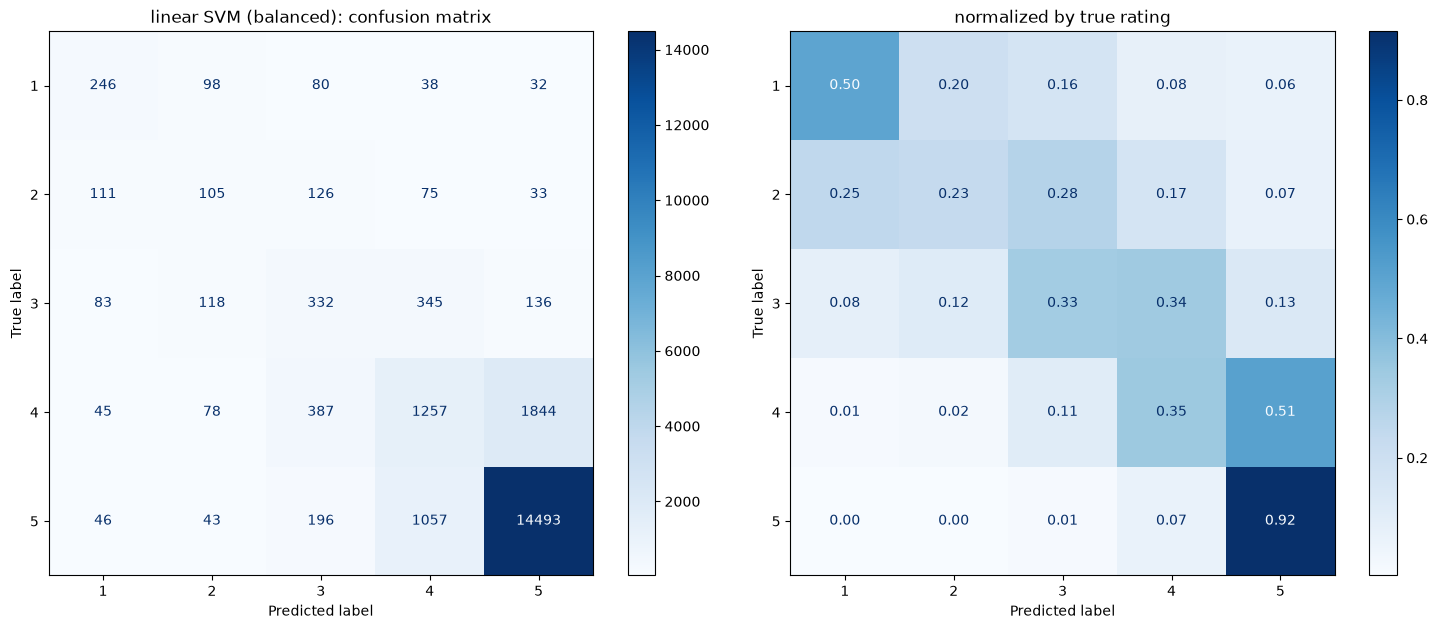

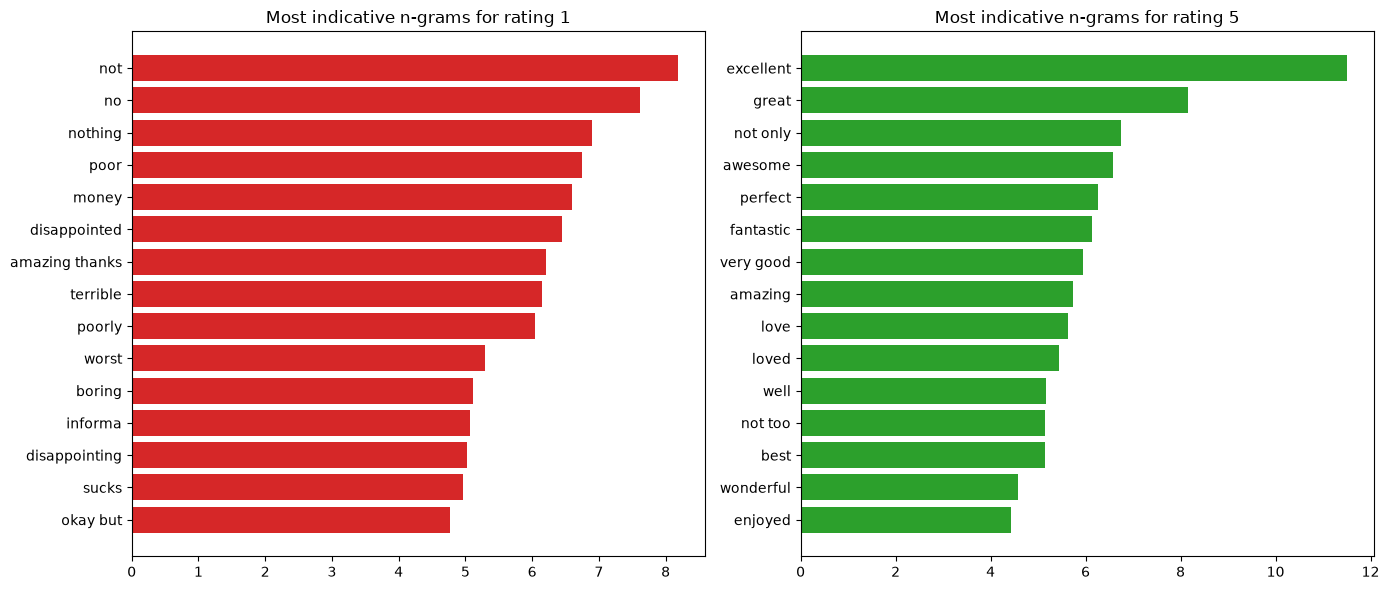

                                                     review  predicted rating
The best course I have ever taken, very clear explanations!                 5
          Boring lectures and the assignments were useless.                 1
              It was ok, some parts are good but too basic.                 4


In [11]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    df = df.dropna(subset=["Review"])
    print(df["Label"].value_counts().sort_index().to_string())
    X_train, X_test, y_train, y_test = train_test_split(df["Review"], df["Label"], test_size=0.2, stratify=df["Label"], random_state=42)

    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_features=200000, sublinear_tf=True, stop_words=None)
    train_vectors = vectorizer.fit_transform(X_train)
    test_vectors = vectorizer.transform(X_test)

    candidates = {
        "logistic regression": LogisticRegression(max_iter=2000, C=4),
        "logistic regression (balanced)": LogisticRegression(max_iter=2000, C=4, class_weight="balanced"),
        "linear SVM (balanced)": LinearSVC(C=0.5, class_weight="balanced"),
    }
    rows, fitted = [], {}
    for name, model in candidates.items():
        model.fit(train_vectors, y_train)
        predictions = model.predict(test_vectors)
        fitted[name] = predictions
        rows.append({
            "model": name,
            "accuracy": accuracy_score(y_test, predictions),
            "macro f1": f1_score(y_test, predictions, average="macro"),
            "weighted f1": f1_score(y_test, predictions, average="weighted"),
            "MAE (stars)": mean_absolute_error(y_test, predictions),
        })
    summary = pd.DataFrame(rows).set_index("model").sort_values("macro f1", ascending=False)
    print(summary.round(4).to_string())

    best = summary.index[0]
    predictions = fitted[best]
    print(f"\nbest model by macro f1: {best}")
    print(classification_report(y_test, predictions, digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues", ax=axes[0], values_format="d")
    axes[0].set_title(f"{best}: confusion matrix")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, normalize="true", cmap="Blues", ax=axes[1], values_format=".2f")
    axes[1].set_title("normalized by true rating")
    fig.tight_layout()
    fig.savefig("images/coursera_confusion_matrix.png", dpi=120)
    plt.show()

    model = candidates["logistic regression (balanced)"]
    terms = np.array(vectorizer.get_feature_names_out())
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, label, color in zip(axes, [1, 5], ["tab:red", "tab:green"]):
        weights = model.coef_[list(model.classes_).index(label)]
        top = np.argsort(weights)[-15:]
        ax.barh(terms[top], weights[top], color=color)
        ax.set_title(f"Most indicative n-grams for rating {label}")
    fig.tight_layout()
    fig.savefig("images/coursera_top_ngrams.png", dpi=120)
    plt.show()

    examples = ["The best course I have ever taken, very clear explanations!", "Boring lectures and the assignments were useless.", "It was ok, some parts are good but too basic."]
    print(pd.DataFrame({"review": examples, "predicted rating": candidates[best].predict(vectorizer.transform(examples))}).to_string(index=False))

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)